# Clase 30/10 — Procesamiento de señales

Continuación de las clases del [9/10](clase_9-10.ipynb), [16/10](clase_16-10.ipynb) y [23/10](clase_23-10.ipynb).

## Preparación: cargar las clases anteriores

La siguiente celda ejecuta `clase_23-10.ipynb`, que carga las clases del 16/10 y del 9/10. Quedan disponibles sus funciones y variables para usarlas directamente en las nuevas celdas. No hace falta ejecutar los otros notebooks por separado.

También se ejecutan sus ejemplos, gráficos y la simulación Monte Carlo del punto 11. Esa simulación puede demorar y, con semilla no fijada, sus resultados cambian ligeramente entre ejecuciones.

Guardar los cuatro notebooks en la misma carpeta y usar esa carpeta como directorio de trabajo. En Colab, subir los tres notebooks anteriores al directorio de trabajo de la sesión. Guardar cualquier cambio en una clase anterior antes de volver a ejecutar la carga.

Al ejecutar **Run All** se recorre la cadena: 9/10 → 16/10 → 23/10 → 30/10.

Binario de 8 bits: 10110010
Vector w (menor peso primero): [0, 1, 0, 0, 1, 1, 0, 1]
s(w) = 178; esperado = 178
SF = 8; B = 125000 Hz; Ts = 0.002048 s = 2.048 ms
Comprobación correcta.
00000000 -> 0: correcto; SF = 8; Ts = 0.002048 s = 2.048 ms
01010101 -> 85: correcto; SF = 8; Ts = 0.002048 s = 2.048 ms
10110010 -> 178: correcto; SF = 8; Ts = 0.002048 s = 2.048 ms
11111111 -> 255: correcto; SF = 8; Ts = 0.002048 s = 2.048 ms
Vector de enteros: [0, 85, 178, 255]
Todas las comprobaciones fueron correctas.
Símbolo: 178; SF: 8; muestras discretas: 256; puntos por gráfico: 8193; Ts: 2.048 ms
Comprobaciones correctas. Vista temporal con sobremuestreo.


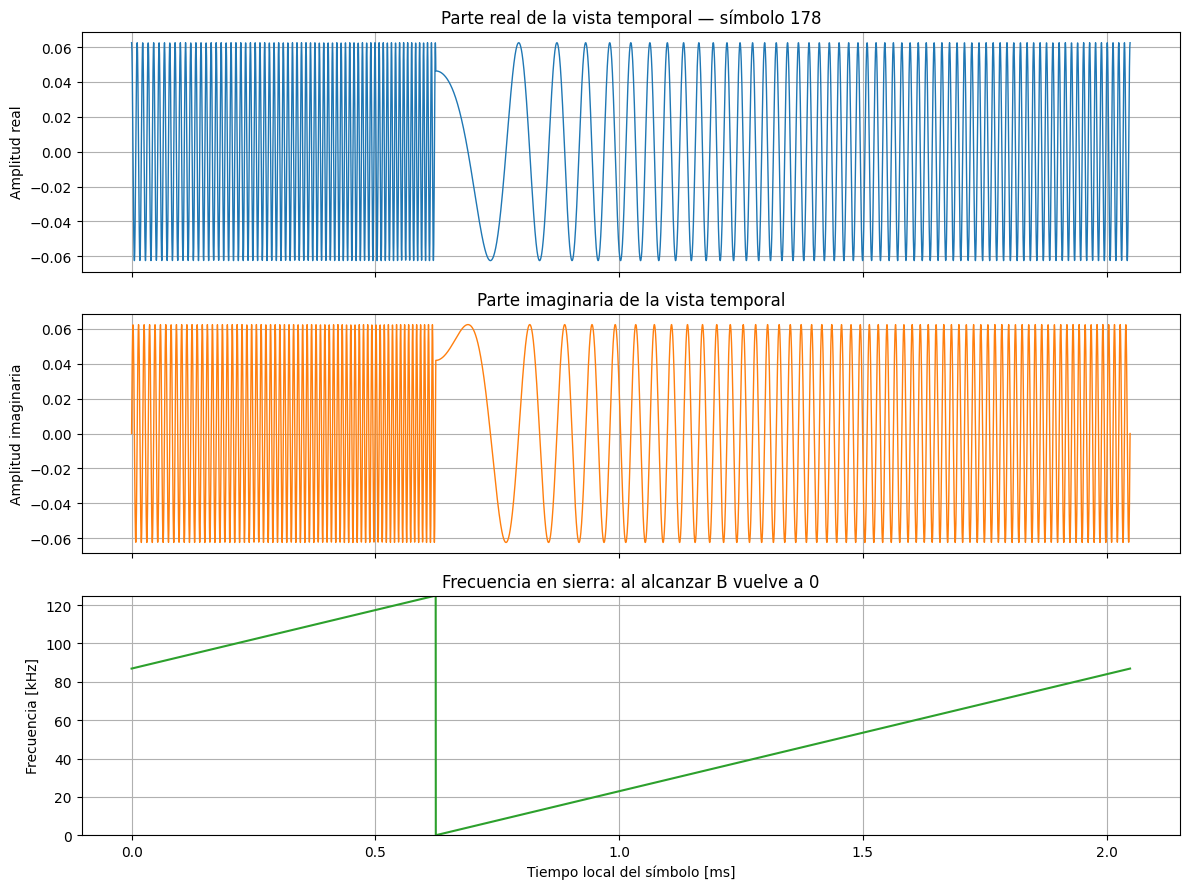

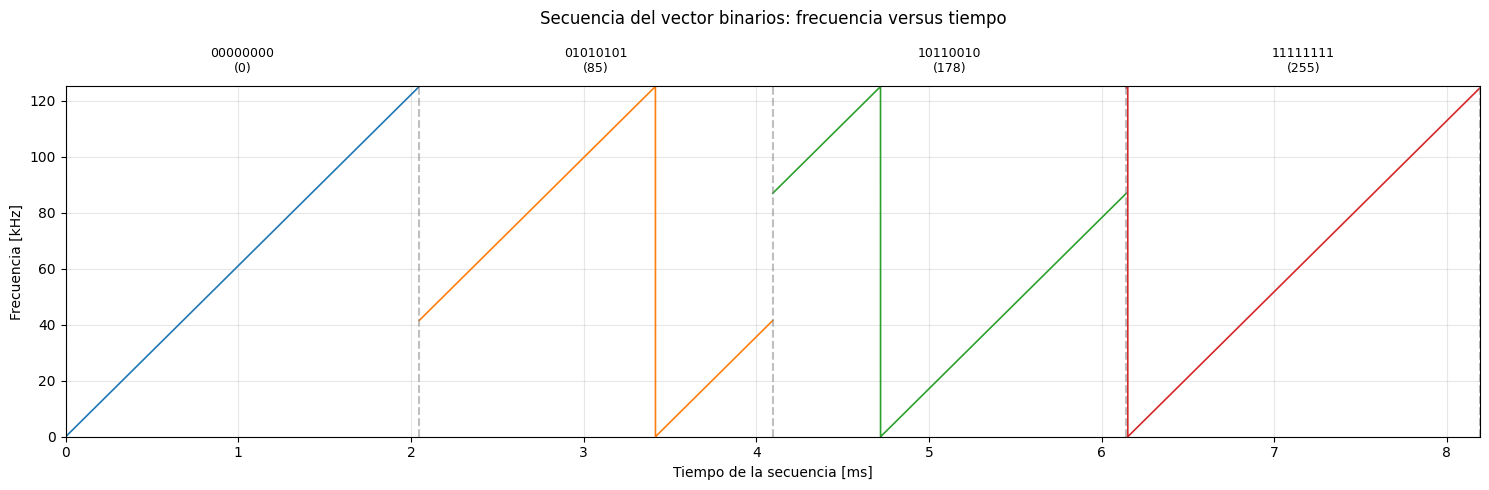

Símbolos recibidos: 4
Muestras por símbolo: 256
Muestras totales: 1024
Duración de la secuencia: 8.192 ms
Canal ideal: todas las muestras recibidas coinciden con las enviadas.
Dechirping correcto: cada fila de d es el tono esperado.


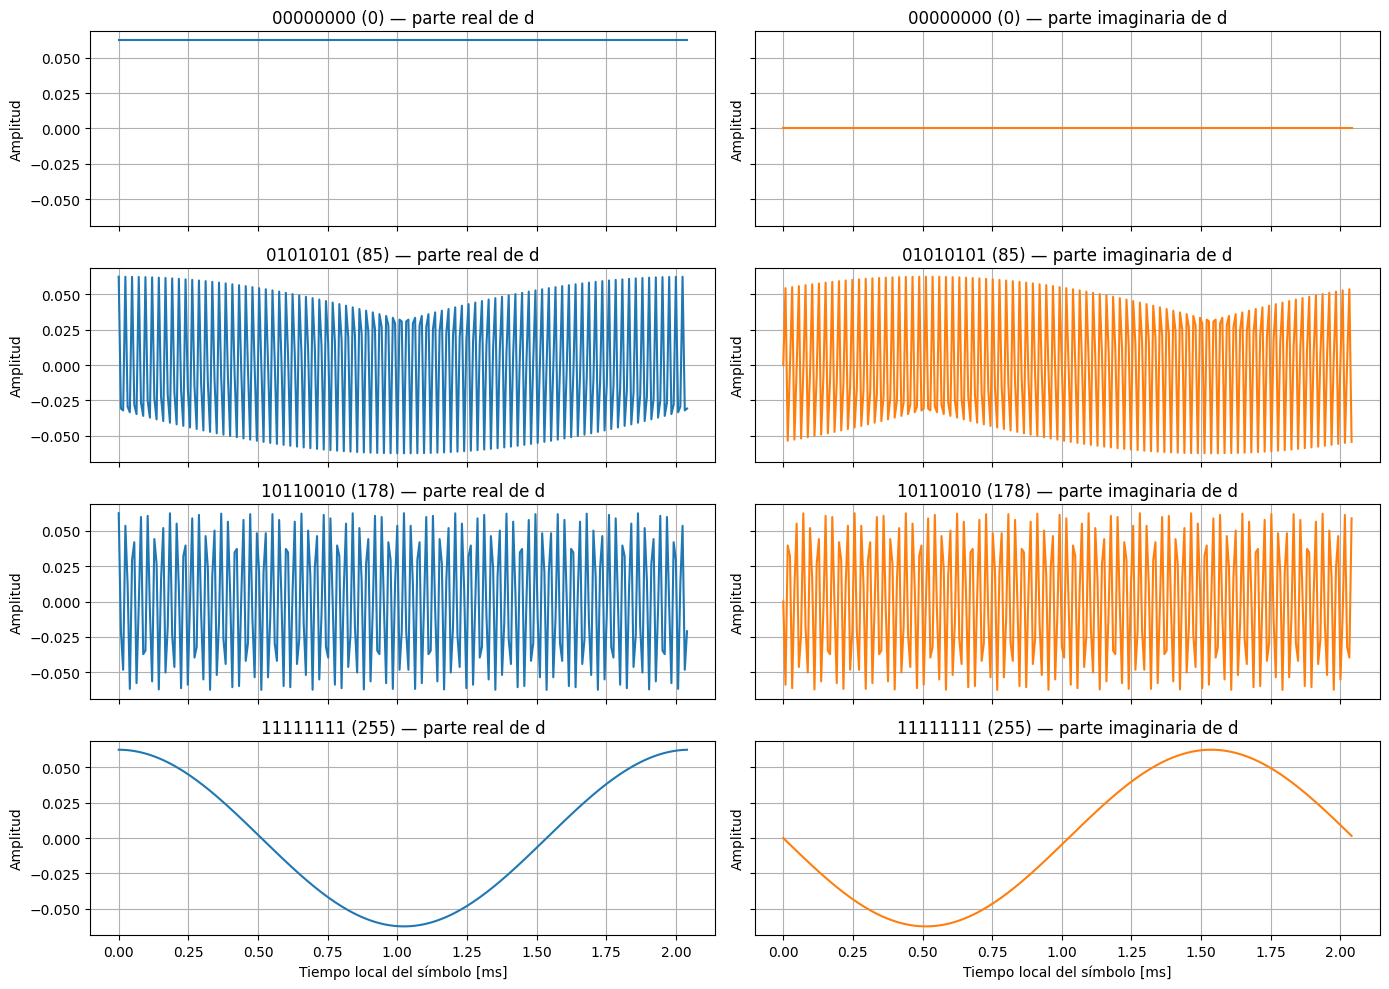

FFT normalizada: coincide con los productos internos calculados directamente.


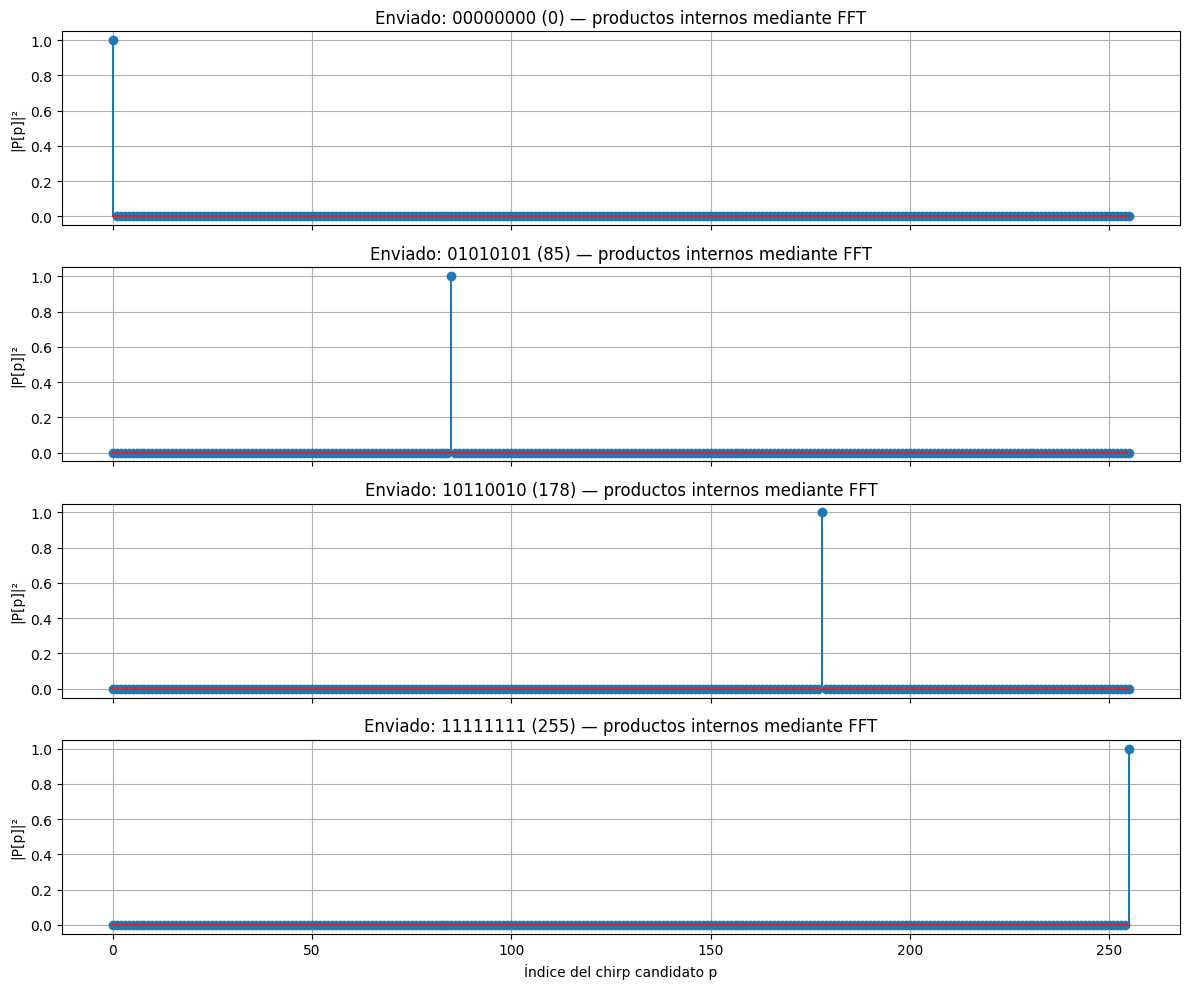

Símbolo 0: enviado = 0; estimado = 0
Símbolo 1: enviado = 85; estimado = 85
Símbolo 2: enviado = 178; estimado = 178
Símbolo 3: enviado = 255; estimado = 255
Secuencia estimada: [  0  85 178 255]
Errores de símbolo: 0
Binarios enviados: ['00000000', '01010101', '10110010', '11111111']
Binarios recibidos: ['00000000', '01010101', '10110010', '11111111']
Bits errados: 0 / 32
BER = 0.000000 (0.00%)
BER de prueba = 0.25 (25%)
Potencia/varianza teórica: 0.01
Media medida: (-0.002068736840596871-0.0055022981646070555j)
Varianza medida: 0.010003
Potencia medida: 0.010037


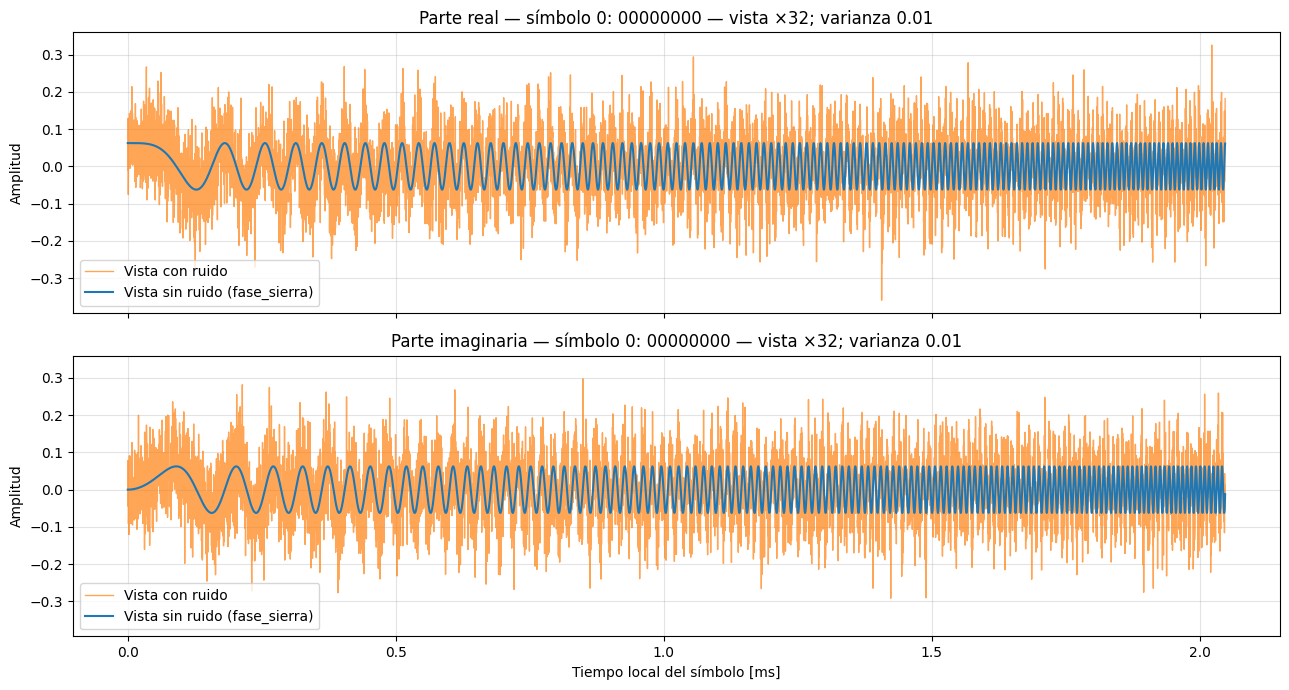

Binarios enviados: ['00000000', '01010101', '10110010', '11111111']
Binarios recibidos con ruido: ['00000000', '01010101', '10110010', '11111111']
BER con ruido = 0.000000 (0.00%)
Potencia de señal: 0.00390625
Potencia/varianza de ruido requerida: 0.00039063
Desviación por componente: 0.01397542
SNR objetivo: 10.00 dB
SNR medida: 9.98 dB
Binarios recibidos: ['00000000', '01010101', '10110010', '11111111']
BER para SNR objetivo de 10.00 dB: 0.000000


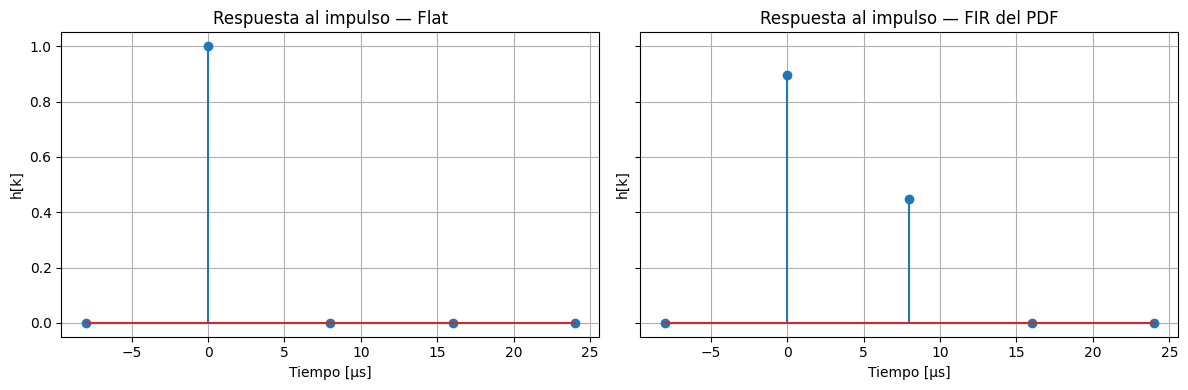

Retardo del segundo camino: 8.000 µs
Energía de h_FIR: 1.000
Muestras en la ventana de recepción: 1024
Muestras de cola FIR conservadas: 1


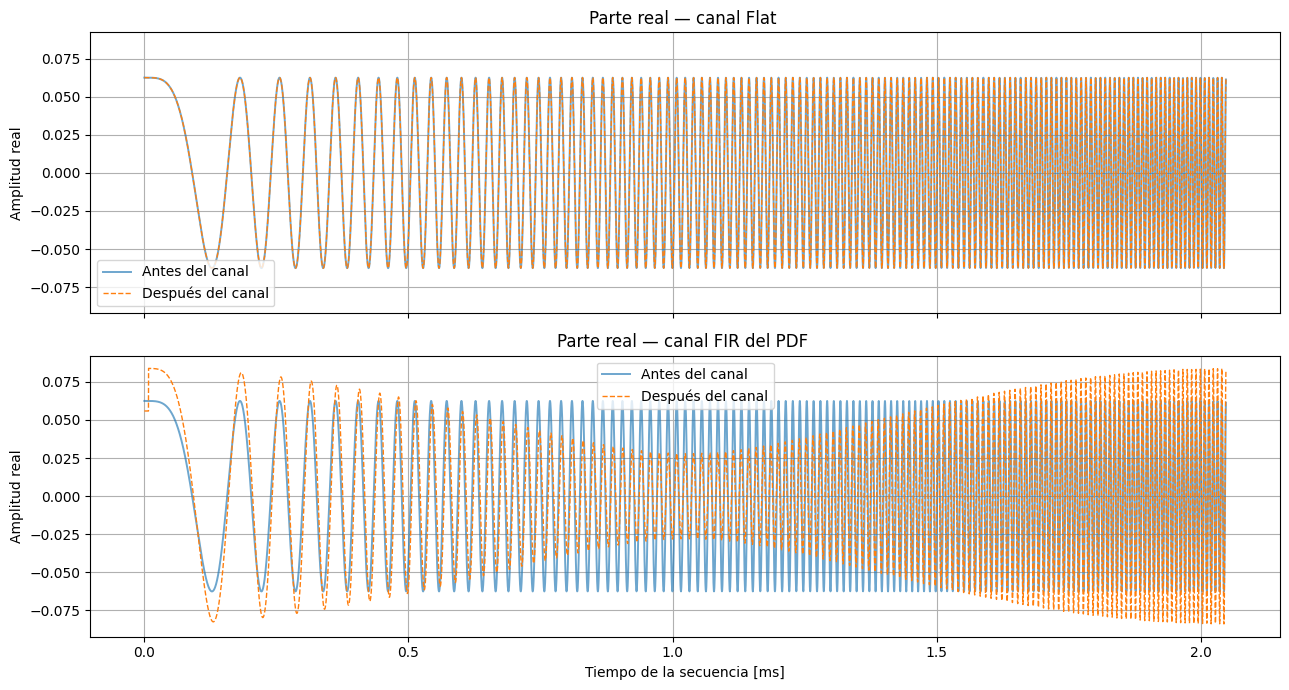

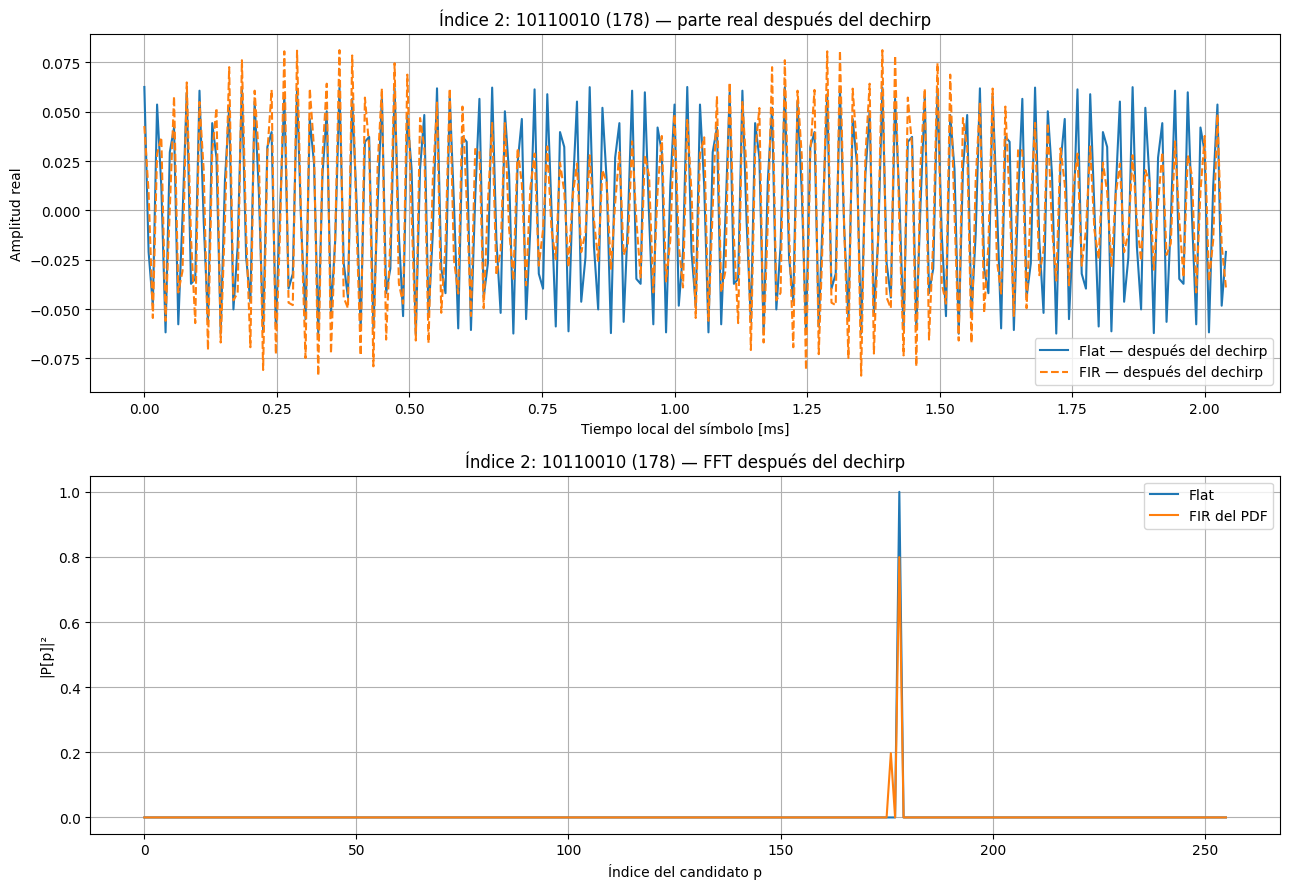

Flat: símbolos estimados = [  0  85 178 255]; BER = 0.000000
FIR del PDF: símbolos estimados = [  0  85 178 255]; BER = 0.000000
Control sin ruido — Flat: BER = 0
Control sin ruido — FIR: BER = 0
SNR=-15 dB | BER=1.952e-01 (15616 errores sobre 80000 bits)
Potencia señal=0.003906; potencia ruido medida=0.123508; sigma=0.351463

Canal FIR
SNR=-12.0 dB | símbolos= 10000 | bits=  80000 | errores=2446 | BER=3.058e-02
SNR=-11.0 dB | símbolos= 10000 | bits=  80000 | errores= 895 | BER=1.119e-02
SNR=-10.0 dB | símbolos= 10000 | bits=  80000 | errores= 274 | BER=3.425e-03
SNR= -9.0 dB | símbolos= 10000 | bits=  80000 | errores= 117 | BER=1.463e-03
SNR= -8.0 dB | símbolos= 20000 | bits= 160000 | errores= 106 | BER=6.625e-04
SNR= -7.0 dB | símbolos=110000 | bits= 880000 | errores= 113 | BER=1.284e-04
SNR= -6.0 dB | símbolos=230000 | bits=1840000 | errores= 108 | BER=5.870e-05

Canal Flat
SNR=-13.0 dB | símbolos= 10000 | bits=  80000 | errores=2374 | BER=2.967e-02
SNR=-12.0 dB | símbolos= 10000 | 

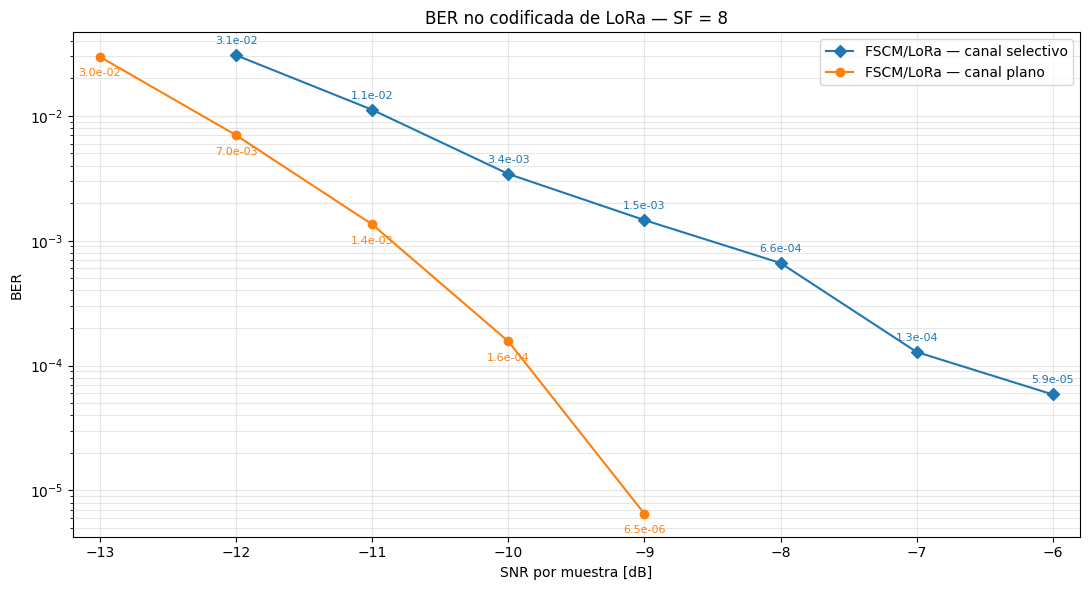

In [31]:
%run ./clase_23-10.ipynb


## 12. Construcción de la trama del ejercicio

Armamos, en este orden:

| Parte | Contenido | Duración | Muestras |
| --- | --- | --- | --- |
| Preámbulo | 8 upchirps del símbolo cero | $8T_s$ | $8N$ |
| Delimitador | 2 downchirps completos y el primer cuarto de otro | $2.25T_s$ | $2N+N/4$ |
| Payload | 10 símbolos de datos | $10T_s$ | $10N$ |
| Total | Trama completa | $20.25T_s$ | $81N/4$ |

Usamos $N=2^{SF}$, $T=1/B$ y $T_s=N/B$. Exigimos SF ≥ 2 para que $N/4$ sea un número entero de muestras. La última muestra está un intervalo $T$ antes del final de la trama.

El upchirp base es el primer resultado de `modular_simbolo(0, SF, B)`. El downchirp de la trama es su conjugado complejo: conserva el módulo $1/\sqrt{N}$ y cambia el signo de la fase. A diferencia del multiplicador de dechirping del receptor, aquí mantenemos la normalización de una señal transmitida.

Esta es la estructura didáctica solicitada. No añadimos los dos símbolos de sync word, cabecera, codificación ni CRC de una trama de radio completa. Como referencia, la [descripción de OpenLoRa, apéndice A](https://www.microsoft.com/en-us/research/wp-content/uploads/2023/08/2023_NSDI_OpenLoRa__Validating_LoRa_Implementations_through_an_Extensible_and_Open_sourced_Framework.pdf) distingue los símbolos de sincronización de los 2.25 downchirps.

Se conservan las muestras discretas de nuestros notebooks para construir `trama["senal"]`. El gráfico de frecuencia se genera por separado usando la vista de un barrido de `fase_sierra`; esa ilustración no sustituye las muestras discretas, como ya distinguimos en las clases anteriores.


In [32]:
def validar_payload_trama(payload, SF, B):
    """Valida los diez enteros y los parámetros de la trama del ejercicio."""
    if not isinstance(SF, (int, np.integer)) or SF < 2:
        raise ValueError("SF debe ser un entero mayor o igual a 2.")
    validar_parametros_modulacion(0, SF, B, 1, 2 ** SF)
    if payload.ndim != 1 or payload.size != 10:
        raise ValueError("El payload debe contener exactamente 10 símbolos enteros.")
    if not np.issubdtype(payload.dtype, np.integer):
        raise ValueError("Los símbolos del payload deben ser enteros.")
    if np.any(payload < 0) or np.any(payload >= 2 ** SF):
        raise ValueError(f"Los símbolos deben estar entre 0 y {2 ** SF - 1}.")


In [33]:
def armar_trama_lora(payload, SF, B, factor_vista=32):
    """Construye la trama discreta y su vista ilustrativa de frecuencia."""
    payload = np.asarray(payload)
    validar_payload_trama(payload, SF, B)
    if not isinstance(factor_vista, (int, np.integer)) or factor_vista < 1:
        raise ValueError("factor_vista debe ser un entero positivo.")
    N = 2 ** SF
    Ts = N / B

    # Cada modulación entrega las muestras discretas y su vista por separado.
    base = modular_simbolo(0, SF, B, muestras_por_muestra=factor_vista) # Genera un upchirp con un factor de vista mayor para visualizar la frecuencia
    modulados_payload = [
        modular_simbolo(int(valor), SF, B, muestras_por_muestra=factor_vista)
        for valor in payload
    ]                                                   # Genera los símbolos modulados para el payload
    upchirp = base[0]                                   # Obtiene el upchirp base
    downchirp = np.conj(upchirp)                        # Obtiene el downchirp base
    simbolos_payload = np.stack([modulado[0] for modulado in modulados_payload])    # Arma una matriz con los símbolos modulados del payload

    preambulo = np.tile(upchirp, 8)                                             # Crea el preámbulo repitiendo el upchirp 8 veces  
    delimitador = np.concatenate([downchirp, downchirp, downchirp[:N // 4]])    # Crea el delimitador concatenando dos downchirps completos y un cuarto de downchirp
    senal = np.concatenate([preambulo, delimitador, simbolos_payload.ravel()])  # Concatena el preámbulo, el delimitador y los símbolos del payload para formar la señal completa
    inicio_downchirps = preambulo.size
    inicio_payload = inicio_downchirps + delimitador.size                       # Calcula el índice de inicio del payload en la señal completa

    # Vista de un barrido: se construye aquí, nunca dentro del gráfico.
    frecuencia_up = base[4][:-1]                            # Excluir el extremo compartido entre símbolos.
    frecuencia_down = B - frecuencia_up                     # Calcula la frecuencia del downchirp a partir de la frecuencia del upchirp
    frecuencia = np.concatenate([
        np.tile(frecuencia_up, 8),
        frecuencia_down, frecuencia_down,
        frecuencia_down[:N * factor_vista // 4],
        *[modulado[4][:-1] for modulado in modulados_payload],
    ])                                                      # Construye la vista de frecuencia concatenando las frecuencias del preámbulo, delimitador y payload
    vista = {
        "factor": factor_vista,
        "frecuencia": frecuencia,
        "tiempo": np.arange(frecuencia.size) / (B * factor_vista),
        "inicio_downchirps": inicio_downchirps * factor_vista,
        "inicio_payload": inicio_payload * factor_vista,
    }

    return {
        "senal": senal,
        "tiempo": np.arange(senal.size) / B,
        "SF": SF, "B": B, "N": N, "Ts": Ts,
        "duracion": senal.size / B,
        "upchirp": upchirp, "downchirp": downchirp,
        "preambulo": preambulo, "delimitador": delimitador,
        "payload": payload.copy(), "simbolos_payload": simbolos_payload,
        "inicio_downchirps": inicio_downchirps,
        "inicio_payload": inicio_payload,
        "vista": vista,
    }


### Ejemplo: construir y comprobar la trama

Los parámetros tienen nombres propios para no sobrescribir los de clases anteriores. Modificar `PAYLOAD_TRAMA` permite elegir los 10 enteros. Con SF = 7, sus valores deben estar entre 0 y 127. El payload empieza a los 10.25 tiempos de símbolo, por lo que su primer índice no es múltiplo de N: no hay que separar toda la trama en bloques de N desde cero para extraer los datos.


In [34]:
SF_TRAMA = 8
B_TRAMA = 125_000
PAYLOAD_TRAMA = [0, 5, 17, 31, 48, 63, 79, 95, 111, 127]

FACTOR_VISTA_TRAMA = 32
trama = armar_trama_lora(PAYLOAD_TRAMA, SF_TRAMA, B_TRAMA, factor_vista=FACTOR_VISTA_TRAMA)
N_TRAMA = trama["N"]
TS_TRAMA = trama["Ts"]

assert trama["preambulo"].size == 8 * N_TRAMA
assert trama["delimitador"].size == 2 * N_TRAMA + N_TRAMA // 4
assert trama["senal"].size == 81 * N_TRAMA // 4
assert np.isclose(trama["duracion"], 20.25 * TS_TRAMA)
assert np.allclose(trama["preambulo"].reshape(8, N_TRAMA), trama["upchirp"])
assert np.allclose(trama["delimitador"][-N_TRAMA // 4:], trama["downchirp"][:N_TRAMA // 4])
assert np.allclose(trama["senal"][trama["inicio_payload"]:].reshape(10, N_TRAMA),
                   trama["simbolos_payload"])
assert np.allclose(np.abs(trama["senal"]), 1 / np.sqrt(N_TRAMA))

print(f"N = {N_TRAMA}; Ts = {TS_TRAMA * 1000:.3f} ms")
print(f"Preámbulo: {trama['preambulo'].size} muestras; duración {8 * TS_TRAMA * 1000:.3f} ms")
print(f"Downchirps: {trama['delimitador'].size} muestras; duración {2.25 * TS_TRAMA * 1000:.3f} ms")
print(f"Payload: {trama['simbolos_payload'].size} muestras; 10 símbolos")
print(f"Inicio del payload: muestra {trama['inicio_payload']}")
print(f"Trama completa: {trama['senal'].size} muestras; duración {trama['duracion'] * 1000:.3f} ms")
print("Payload:", trama["payload"])


N = 256; Ts = 2.048 ms
Preámbulo: 2048 muestras; duración 16.384 ms
Downchirps: 576 muestras; duración 4.608 ms
Payload: 2560 muestras; 10 símbolos
Inicio del payload: muestra 2624
Trama completa: 5184 muestras; duración 41.472 ms
Payload: [  0   5  17  31  48  63  79  95 111 127]


### Vista de frecuencia: preámbulo, downchirps y payload

`armar_trama_lora` construye tanto las muestras discretas como la vista de frecuencia. Esta celda solo dibuja `trama["vista"]`: no vuelve a modular ni a concatenar los símbolos. El detalle temporal se elige con `FACTOR_VISTA_TRAMA` al construir la trama.

La vista reutiliza la frecuencia ilustrativa de `modular_simbolo`, basada en `fase_sierra`. Para los downchirps usa `B - frecuencia_up`; el cuarto de downchirp corresponde al primer cuarto del barrido. Los límites guardados en la trama determinan los colores y los tiempos. Esta vista no se obtiene estimando la frecuencia de `trama["senal"]`: conserva la distinción entre el modelo discreto de procesamiento y la ilustración de un barrido.


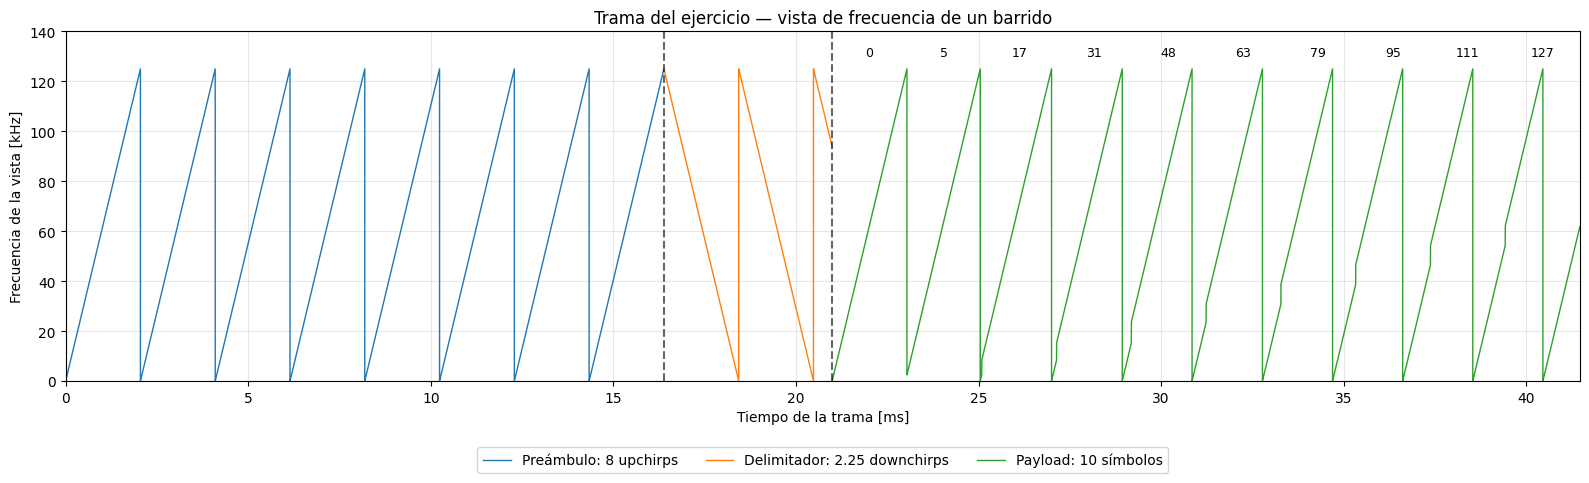

In [35]:
# Solo dibujamos los datos ya construidos por armar_trama_lora.
vista = trama["vista"]
limite_down = vista["inicio_downchirps"]
limite_payload = vista["inicio_payload"]
fig_trama, eje_trama = plt.subplots(figsize=(16, 5))

for inicio, fin, nombre, color in (
    (0, limite_down, "Preámbulo: 8 upchirps", "tab:blue"),
    (limite_down, limite_payload, "Delimitador: 2.25 downchirps", "tab:orange"),
    (limite_payload, len(vista["frecuencia"]), "Payload: 10 símbolos", "tab:green"),
):
    eje_trama.plot(vista["tiempo"][inicio:fin] * 1000,
                   vista["frecuencia"][inicio:fin] / 1000,
                   color=color, label=nombre, linewidth=1)

for limite in (trama["inicio_downchirps"], trama["inicio_payload"]):
    eje_trama.axvline(limite / trama["B"] * 1000, color="black", linestyle="--", alpha=0.6)
for i, valor in enumerate(trama["payload"]):
    centro = (trama["inicio_payload"] / trama["B"] + (i + 0.5) * trama["Ts"]) * 1000
    eje_trama.text(centro, trama["B"] / 1000 * 1.04, str(valor), ha="center", fontsize=9)

eje_trama.set(title="Trama del ejercicio — vista de frecuencia de un barrido",
              xlabel="Tiempo de la trama [ms]", ylabel="Frecuencia de la vista [kHz]")
eje_trama.set_xlim(0, trama["duracion"] * 1000)
eje_trama.set_ylim(0, trama["B"] / 1000 * 1.12)
eje_trama.grid(True, alpha=0.3)
eje_trama.legend(loc="upper center", bbox_to_anchor=(0.5, -0.17), ncol=3)
fig_trama.tight_layout()
plt.show()


## 13. Detección temporal por correlación normalizada

El receptor conoce SF, B y la estructura esperada, pero no dónde empieza la trama dentro de la captura. Construimos su propia plantilla con 8 upchirps de símbolo cero y 2.25 downchirps, sin utilizar el payload ni el comienzo real de la captura. Incluimos los downchirps para distinguir mejor el encabezado completo de una repetición de upchirps. Esto puede reducir ambigüedades, pero no garantiza una probabilidad de falsa alarma concreta sin estudiar ruido y umbral.

Para cada inicio candidato $\ell$, tomamos una ventana de la misma longitud $M$ que la plantilla $p$ y calculamos:

$$C[\ell]=\sum_{k=0}^{M-1}r[\ell+k]p^*[k],$$
$$\rho[\ell]=\frac{|C[\ell]|}{\sqrt{\left(\sum_{k=0}^{M-1}|r[\ell+k]|^2\right)
\left(\sum_{k=0}^{M-1}|p[k]|^2\right)}}.$$

Usamos **energías de la ventana y de la plantilla**, no la energía de toda la captura. La raíz del producto permite que $\rho$ quede entre 0 y 1 y valga 1 para una coincidencia exacta, incluso con una ganancia o fase constante distinta de cero. Las ventanas sin energía se asignan a cero. No es una probabilidad de que haya un preámbulo.

Buscamos el máximo y exigimos que supere `UMBRAL_TIEMPO`, porque toda captura, incluso una de ruido, tiene un máximo. Con ruido la coincidencia suele ser menor que 1. El umbral del ejemplo es ilustrativo y deberá ajustarse si cambiamos la SNR o introducimos un FIR, errores de frecuencia o un modelo distinto.

La implementación usa correlación directa en el tiempo (`np.correlate`), sin FFT. Se analizan solo ventanas completas (`mode="valid"`). El índice del resultado es el **inicio de la ventana**; para calcularlo ya se debe haber recibido el encabezado completo de 10.25 Ts. Este ejemplo busca una trama en una captura finita; no es todavía un detector de múltiples tramas ni un algoritmo por bloques en tiempo real.


In [36]:
def crear_plantilla_preambulo(SF, B, incluir_downchirps=True):
    """Plantilla local del receptor; no depende del payload transmitido."""
    if not isinstance(SF, (int, np.integer)) or SF < 2:
        raise ValueError("SF debe ser un entero mayor o igual a 2.")
    up = modular_simbolo(0, SF, B, muestras_por_muestra=1)[0]
    preambulo = np.tile(up, 8)
    if not incluir_downchirps:
        return preambulo

    down = np.conj(up)
    return np.concatenate([preambulo, down, down, down[:len(up) // 4]])


In [37]:
def validar_correlacion_temporal(recibida, plantilla):
    """Verifica las entradas de la correlación antes de calcularla."""
    for nombre, vector in (("recibida", recibida), ("plantilla", plantilla)):
        if vector.ndim != 1 or vector.size == 0:
            raise ValueError(f"{nombre} debe ser un vector no vacío.")
        if not np.all(np.isfinite(vector)):
            raise ValueError(f"{nombre} debe contener muestras finitas.")
    if recibida.size < plantilla.size:
        raise ValueError("La captura debe contener al menos una ventana completa de la plantilla.")
    if np.sum(np.abs(plantilla) ** 2) == 0:
        raise ValueError("La plantilla debe tener energía distinta de cero.")


In [38]:
def correlacion_temporal_normalizada(recibida, plantilla):
    """Devuelve un valor de coincidencia por inicio válido de ventana."""
    # Controlamos que todo este bien antes de calcular la correlación.
    recibida = np.asarray(recibida, dtype=complex)                      
    plantilla = np.asarray(plantilla, dtype=complex)
    validar_correlacion_temporal(recibida, plantilla)
    M = plantilla.size

    # np.correlate conjuga el segundo argumento: no conjugarlo de nuevo.
    correlacion = np.correlate(recibida, plantilla, mode="valid")   # Calcula la correlación cruzada entre la señal recibida y la plantilla
    energia_plantilla = np.sum(np.abs(plantilla) ** 2)

    # Energía de cada ventana mediante suma acumulada, sin repetir sumas de M términos.
    acumulada = np.r_[0.0, np.cumsum(np.abs(recibida) ** 2, dtype=float)]   # Calcula la suma acumulada de la energía de la señal recibida
    energia_ventanas = np.maximum(acumulada[M:] - acumulada[:-M], 0.0)      # Calcula la energía de cada ventana de la señal recibida
    denominador = np.sqrt(energia_plantilla * energia_ventanas)             # Calcula el denominador para normalizar la correlación 
    coincidencia = np.zeros(correlacion.size)                               
    np.divide(np.abs(correlacion), denominador, out=coincidencia, where=denominador > 0)    # Calcula la coincidencia normalizada evitando divisiones por cero
    return np.clip(coincidencia, 0.0, 1.0)  # Limitar pequeños errores de redondeo.


def detectar_preambulo_tiempo(recibida, plantilla, umbral=0.8):
    """Busca una coincidencia máxima y decide si supera el umbral."""
    if not np.isscalar(umbral) or not np.isrealobj(umbral) or not 0 < umbral <= 1:
        raise ValueError("El umbral debe estar entre 0 (excluido) y 1.")

    coincidencia = correlacion_temporal_normalizada(recibida, plantilla)    # Calcula la coincidencia normalizada entre la señal recibida y la plantilla
    indice_maximo = int(np.argmax(coincidencia))                            # Obtiene el índice del valor máximo de coincidencia
    maximo = float(coincidencia[indice_maximo])                             # Obtiene el valor máximo de coincidencia
    detectado = maximo >= umbral                                            # Verifica si el valor máximo de coincidencia supera el umbral
    return {
        "detectado": detectado,
        "inicio_preambulo": indice_maximo if detectado else None,
        "indice_maximo": indice_maximo,
        "coincidencia_maxima": maximo,
        "coincidencia": coincidencia,
        "umbral": umbral,
    }


### Ejemplo: trama con comienzo desconocido en el receptor

Simulamos un tiempo de espera antes de la trama y otro después. El desplazamiento no es múltiplo de Ts, para comprobar que se busca muestra por muestra. `RETARDO_PRUEBA` es información de la prueba: nunca se pasa al detector, solo se utiliza después para verificar su resultado.

Primero buscamos en la captura ideal. Luego sumamos ruido a **toda** la captura, incluidos los intervalos sin transmisión. La potencia del ruido se calcula respecto de la señal activa de la trama, no del promedio de la captura con silencios. Usamos SNR = 10 dB y semilla fija para repetir el ejemplo.


In [39]:
UMBRAL_TIEMPO = 0.8
SNR_DETECCION_DB = 10.0
SEMILLA_DETECCION = 123
RETARDO_PRUEBA = 3 * N_TRAMA + N_TRAMA // 3
MUESTRAS_POSTERIORES = 2 * N_TRAMA

plantilla_receptor = crear_plantilla_preambulo(SF_TRAMA, B_TRAMA)
captura_ideal = np.concatenate([
    np.zeros(RETARDO_PRUEBA, dtype=complex),
    trama["senal"],
    np.zeros(MUESTRAS_POSTERIORES, dtype=complex)       # Arma la captura ideal agregando ceros antes y después de la señal de la trama
])                                                      

parametros_deteccion = calcular_parametros_ruido(trama["senal"], SNR_DETECCION_DB)  # Calcula los parámetros de ruido para la detección a partir de la señal de la trama y el SNR deseado
captura_ruidosa, ruido_deteccion = agregar_ruido_gaussiano(
    captura_ideal, parametros_deteccion["sigma2"], semilla=SEMILLA_DETECCION        # Agrega ruido gaussiano a la captura ideal para simular una señal ruidosa
)

# Validación de la detección de preámbulo en tiempo
resultado_tiempo_ideal = detectar_preambulo_tiempo(captura_ideal, plantilla_receptor, UMBRAL_TIEMPO)
resultado_tiempo_ruido = detectar_preambulo_tiempo(captura_ruidosa, plantilla_receptor, UMBRAL_TIEMPO)

assert np.array_equal(plantilla_receptor, trama["senal"][:trama["inicio_payload"]])
assert resultado_tiempo_ideal["inicio_preambulo"] == RETARDO_PRUEBA
assert np.isclose(resultado_tiempo_ideal["coincidencia_maxima"], 1)

print(f"Plantilla: {plantilla_receptor.size} muestras = 10.25 Ts")
print(f"Inicio real de prueba: muestra {RETARDO_PRUEBA} ({RETARDO_PRUEBA / B_TRAMA * 1000:.3f} ms)")
for nombre, resultado in (("Sin ruido", resultado_tiempo_ideal), ("Con ruido", resultado_tiempo_ruido)):
    print(f"{nombre}: detectado={resultado['detectado']}; "
          f"máximo={resultado['coincidencia_maxima']:.4f}; "
          f"inicio estimado={resultado['inicio_preambulo']}")
    if resultado["detectado"]:
        inicio_payload_estimado = resultado["inicio_preambulo"] + plantilla_receptor.size
        print(f"  Inicio del payload por estructura conocida: muestra {inicio_payload_estimado}")


Plantilla: 2624 muestras = 10.25 Ts
Inicio real de prueba: muestra 853 (6.824 ms)
Sin ruido: detectado=True; máximo=1.0000; inicio estimado=853
  Inicio del payload por estructura conocida: muestra 3477
Con ruido: detectado=True; máximo=0.9541; inicio estimado=853
  Inicio del payload por estructura conocida: muestra 3477


### Máximo de coincidencia y comparación de plantillas

Arriba se muestra el módulo de la captura, solo para localizar la llegada de energía. En el centro se comparan las curvas de coincidencia ideal y ruidosa con el umbral. Abajo comparamos, sobre la misma captura ruidosa, la plantilla completa y una de solo 8 upchirps. La repetición de upchirps puede producir máximos secundarios separados por Ts; los downchirps añaden una transición característica que ayuda a distinguir el inicio correcto.

El eje de las correlaciones indica el inicio candidato de la plantilla, no el instante en que termina de recibirse. La comparación ilustra esta captura; para medir probabilidades de falsa alarma y de detección se necesitarían muchas realizaciones y casos sin trama.


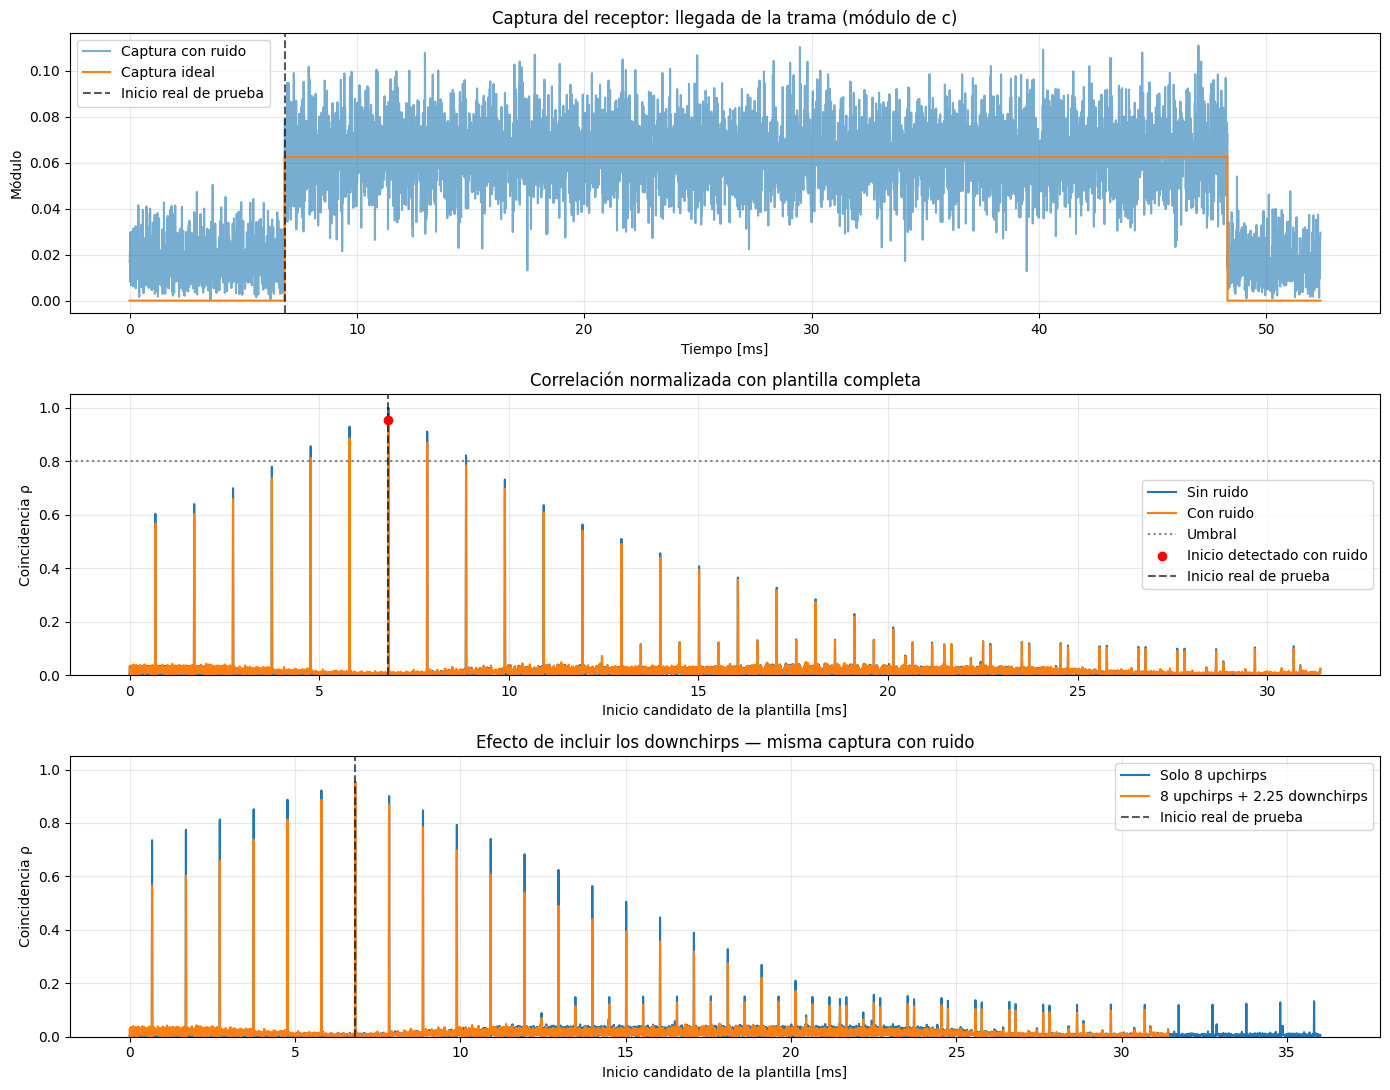

In [40]:
plantilla_solo_up = crear_plantilla_preambulo(SF_TRAMA, B_TRAMA, incluir_downchirps=False)
coincidencia_solo_up = correlacion_temporal_normalizada(captura_ruidosa, plantilla_solo_up)

fig_deteccion_tiempo, ejes_deteccion = plt.subplots(3, 1, figsize=(14, 11))
t_captura = np.arange(captura_ideal.size) / B_TRAMA * 1000
ejes_deteccion[0].plot(t_captura, np.abs(captura_ruidosa), alpha=0.6, label="Captura con ruido")
ejes_deteccion[0].plot(t_captura, np.abs(captura_ideal), label="Captura ideal")
ejes_deteccion[0].set(title="Captura del receptor: llegada de la trama (módulo de c)", ylabel="Módulo")

for nombre, resultado in (("Sin ruido", resultado_tiempo_ideal), ("Con ruido", resultado_tiempo_ruido)):
    t_candidatos = np.arange(resultado["coincidencia"].size) / B_TRAMA * 1000
    ejes_deteccion[1].plot(t_candidatos, resultado["coincidencia"], label=nombre)
ejes_deteccion[1].axhline(UMBRAL_TIEMPO, color="gray", linestyle=":", label="Umbral")
if resultado_tiempo_ruido["detectado"]:
    ejes_deteccion[1].scatter(resultado_tiempo_ruido["inicio_preambulo"] / B_TRAMA * 1000,
                             resultado_tiempo_ruido["coincidencia_maxima"], color="red", zorder=5,
                             label="Inicio detectado con ruido")
ejes_deteccion[1].set(title="Correlación normalizada con plantilla completa", ylabel="Coincidencia ρ")

for curva, nombre in ((coincidencia_solo_up, "Solo 8 upchirps"),
                     (resultado_tiempo_ruido["coincidencia"], "8 upchirps + 2.25 downchirps")):
    ejes_deteccion[2].plot(np.arange(curva.size) / B_TRAMA * 1000, curva, label=nombre)
ejes_deteccion[2].set(title="Efecto de incluir los downchirps — misma captura con ruido", ylabel="Coincidencia ρ")

for i, eje in enumerate(ejes_deteccion):
    eje.axvline(RETARDO_PRUEBA / B_TRAMA * 1000, color="black", linestyle="--", alpha=0.65,
                label="Inicio real de prueba")
    eje.set_xlabel("Tiempo [ms]" if i == 0 else "Inicio candidato de la plantilla [ms]")
    if i > 0:
        eje.set_ylim(0, 1.05)
    eje.grid(True, alpha=0.3)
    eje.legend()
fig_deteccion_tiempo.tight_layout()
plt.show()


## 14. PER y errores para una SNR: plantilla completa

Evaluamos el detector temporal del punto 13 con una SNR elegida. Para cada prueba generamos 10 símbolos de payload aleatorios, armamos la trama del punto 12 y la ubicamos en una posición desconocida para el receptor. Agregamos ruido gaussiano a toda la captura, incluso antes y después de la trama. La SNR se calcula con la potencia de la señal transmitida durante la trama, no con el promedio de los silencios.

Después llamamos a `detectar_preambulo_tiempo` con la plantilla de **8 upchirps + 2.25 downchirps**. Si encuentra el comienzo correcto, extraemos los 10 símbolos desde el fin de esa plantilla y usamos las funciones existentes de dechirp, FFT y decisión para comprobar el payload.

Clasificamos cada trama en una sola categoría:

1. **Omisión:** el máximo no supera el umbral.
2. **Error de sincronización:** supera el umbral, pero el comienzo estimado no coincide exactamente con el real (tolerancia de 0 muestras).
3. **Error de payload:** detecta el comienzo correctamente, pero al menos un bit del payload es incorrecto.
4. **Trama correcta:** detecta el comienzo y todos los bits del payload son correctos.

Con esta convención, el **PER de extremo a extremo** es:

$$PER=\frac{\text{omisiones + errores de sincronización + errores de payload}}{\text{tramas enviadas}}.$$

También medimos la tasa de comienzos correctos y la proporción de errores de bit **solo para los payloads con sincronización correcta**. Esta última es una medida condicional: se indica cuántos bits participaron, y no se calcula si no hay ninguno.

Las **falsas alarmas** se miden aparte: generamos capturas de solo ruido de la misma longitud y contamos en cuántas el detector supera el umbral. La tasa de falsas alarmas es por captura sin trama; no se suma al numerador del PER de tramas enviadas.

Suposiciones de esta prueba: un canal plano con ruido, SF y B conocidos, un comienzo aleatorio en una muestra entera, sin errores de frecuencia o reloj y una sola trama por captura. El detector compara la captura completa y usa el máximo global, igual que en el punto 13. Una muestra finita sin errores no demuestra que la probabilidad real sea cero; aumentar `CANTIDAD_TRAMAS_PER` y `CAPTURAS_SIN_TRAMA` mejora la estimación. El umbral puede afectar tanto las omisiones como las falsas alarmas.


In [41]:
def evaluar_per_plantilla_completa(snr_db, cantidad_tramas, capturas_sin_trama,
                                   SF, B, umbral=0.8, semilla=123):
    """Estima PER y errores del detector del punto 13 para una SNR."""
    for nombre, valor in (("cantidad_tramas", cantidad_tramas),
                          ("capturas_sin_trama", capturas_sin_trama)):
        if not isinstance(valor, (int, np.integer)) or valor < 1:
            raise ValueError(f"{nombre} debe ser un entero positivo.")
    validar_snr(snr_db)

    generador = np.random.default_rng(semilla)
    N = 2 ** SF
    plantilla = crear_plantilla_preambulo(SF, B)
    max_inicio = 2 * N
    # Una trama de referencia fija la longitud de captura y la potencia de señal.
    referencia = armar_trama_lora(np.zeros(10, dtype=int), SF, B, factor_vista=1)
    longitud_captura = max_inicio + referencia["senal"].size + N
    sigma2 = calcular_parametros_ruido(referencia["senal"], snr_db)["sigma2"]

    omisiones = errores_sync = errores_payload = tramas_correctas = 0
    bits_errados = bits_comparados = 0
    errores_temporales = []
    pesos = np.arange(SF - 1, -1, -1)

    for _ in range(cantidad_tramas):
        payload_enviado = generador.integers(0, N, size=10)
        trama_prueba = armar_trama_lora(payload_enviado, SF, B, factor_vista=1)
        inicio_real = int(generador.integers(0, max_inicio + 1))

        captura_limpia = np.zeros(longitud_captura, dtype=complex)
        captura_limpia[inicio_real:inicio_real + trama_prueba["senal"].size] = trama_prueba["senal"]
        captura, _ = agregar_ruido_gaussiano(captura_limpia, sigma2, semilla=generador)
        deteccion = detectar_preambulo_tiempo(captura, plantilla, umbral)

        if not deteccion["detectado"]:
            omisiones += 1
            continue

        inicio_estimado = deteccion["inicio_preambulo"]
        errores_temporales.append(inicio_estimado - inicio_real)
        if inicio_estimado != inicio_real:
            errores_sync += 1
            continue

        inicio_payload = inicio_estimado + plantilla.size
        muestras_payload = captura[inicio_payload:inicio_payload + 10 * N]
        if muestras_payload.size != 10 * N:
            raise RuntimeError("La captura no contiene el payload completo.")
        d_payload, _ = aplicar_dechirp(muestras_payload.reshape(10, N))
        estimados = identificar_simbolo(aplicar_fft(d_payload))
        bits_tx = ((payload_enviado[:, None] >> pesos) & 1).reshape(-1)
        bits_rx = ((estimados[:, None] >> pesos) & 1).reshape(-1)
        errores_bits_trama = int(np.count_nonzero(bits_tx != bits_rx))
        bits_errados += errores_bits_trama
        bits_comparados += bits_tx.size
        if errores_bits_trama:
            errores_payload += 1
        else:
            tramas_correctas += 1

    falsas_alarmas = 0
    for _ in range(capturas_sin_trama):
        silencio = np.zeros(longitud_captura, dtype=complex)
        ruido_solo, _ = agregar_ruido_gaussiano(silencio, sigma2, semilla=generador)
        if detectar_preambulo_tiempo(ruido_solo, plantilla, umbral)["detectado"]:
            falsas_alarmas += 1

    tramas_erradas = omisiones + errores_sync + errores_payload
    return {
        "snr_db": snr_db, "umbral": umbral, "sigma2": sigma2,
        "cantidad_tramas": cantidad_tramas, "tramas_correctas": tramas_correctas,
        "omisiones": omisiones, "errores_sync": errores_sync,
        "errores_payload": errores_payload, "tramas_erradas": tramas_erradas,
        "per": tramas_erradas / cantidad_tramas,
        "detecciones_correctas": errores_payload + tramas_correctas,
        "tasa_sincronizacion_correcta": (errores_payload + tramas_correctas) / cantidad_tramas,
        "bits_errados": bits_errados, "bits_comparados": bits_comparados,
        "ber_condicional": bits_errados / bits_comparados if bits_comparados else None,
        "errores_temporales": np.asarray(errores_temporales, dtype=int),
        "capturas_sin_trama": capturas_sin_trama, "falsas_alarmas": falsas_alarmas,
        "tasa_falsas_alarmas": falsas_alarmas / capturas_sin_trama,
    }


### Ejemplo: estimación para una SNR dada

Podés modificar la SNR, el umbral y la cantidad de pruebas. El valor inicial de 2.5 dB es una condición de prueba para observar el comportamiento con este umbral; no representa un punto calibrado de la figura del PDF. Fijamos la semilla para que puedas repetir el ejemplo; `None` genera otra realización. Las categorías son excluyentes y su suma debe ser la cantidad de tramas enviadas.


In [42]:
SNR_PER_DB = -10
UMBRAL_PER = 0.8
CANTIDAD_TRAMAS_PER = 200
CAPTURAS_SIN_TRAMA = 200
SEMILLA_PER = 42

resultado_per_completo = evaluar_per_plantilla_completa(
    SNR_PER_DB, CANTIDAD_TRAMAS_PER, CAPTURAS_SIN_TRAMA,
    SF_TRAMA, B_TRAMA, umbral=UMBRAL_PER, semilla=SEMILLA_PER
)
r_per = resultado_per_completo

print(f"SNR: {r_per['snr_db']:.2f} dB | umbral: {r_per['umbral']:.2f}")
print(f"Tramas enviadas: {r_per['cantidad_tramas']}")
print(f"Omisiones: {r_per['omisiones']} ({r_per['omisiones'] / CANTIDAD_TRAMAS_PER:.2%})")
print(f"Errores de sincronización: {r_per['errores_sync']} ({r_per['errores_sync'] / CANTIDAD_TRAMAS_PER:.2%})")
print(f"Errores de payload con sincronización correcta: {r_per['errores_payload']} ({r_per['errores_payload'] / CANTIDAD_TRAMAS_PER:.2%})")
print(f"Tramas correctas: {r_per['tramas_correctas']} ({r_per['tramas_correctas'] / CANTIDAD_TRAMAS_PER:.2%})")
print(f"Sincronización correcta: {r_per['detecciones_correctas']} / {CANTIDAD_TRAMAS_PER} = {r_per['tasa_sincronizacion_correcta']:.2%}")
print(f"PER: {r_per['tramas_erradas']} / {CANTIDAD_TRAMAS_PER} = {r_per['per']:.2%}")
print(f"Falsas alarmas: {r_per['falsas_alarmas']} / {CAPTURAS_SIN_TRAMA} = {r_per['tasa_falsas_alarmas']:.2%}")
if r_per["ber_condicional"] is None:
    print("BER condicional: no disponible (ningún payload con sincronización correcta).")
else:
    print(f"BER condicional: {r_per['bits_errados']} / {r_per['bits_comparados']} = {r_per['ber_condicional']:.6g}")

assert r_per["omisiones"] + r_per["errores_sync"] + r_per["errores_payload"] + r_per["tramas_correctas"] == CANTIDAD_TRAMAS_PER
assert r_per["per"] == 1 - r_per["tramas_correctas"] / CANTIDAD_TRAMAS_PER or np.isclose(r_per["per"], 1 - r_per["tramas_correctas"] / CANTIDAD_TRAMAS_PER)


SNR: -10.00 dB | umbral: 0.80
Tramas enviadas: 200
Omisiones: 200 (100.00%)
Errores de sincronización: 0 (0.00%)
Errores de payload con sincronización correcta: 0 (0.00%)
Tramas correctas: 0 (0.00%)
Sincronización correcta: 0 / 200 = 0.00%
PER: 200 / 200 = 100.00%
Falsas alarmas: 0 / 200 = 0.00%
BER condicional: no disponible (ningún payload con sincronización correcta).


## 15. Alternativa temporal: un upchirp y un contador de ocho coincidencias

El receptor guarda solamente un upchirp cero de $N$ muestras. Reutilizamos la correlación normalizada del punto 13, ahora con ventanas de longitud $N$. Una coincidencia aislada no confirma el preámbulo: exigimos ocho consecutivas separadas exactamente por $N$ muestras (un Ts).

Para cada comienzo candidato $\ell$, contamos la coincidencia actual más las anteriores en $\ell-N$, $\ell-2N$, etc. Si falla el umbral, esa cadena se reinicia en cero. En código, `contador[ell]` usa `contador[ell - N]`, no el de la muestra vecina. Así se buscan todos los alineamientos posibles sin contar varias veces un mismo chirp.

Declaramos la primera cadena que alcanza ocho coincidencias. Si la octava ventana comienza en $\ell$, el comienzo estimado del preámbulo es $\ell-7N$ y la última muestra necesaria para confirmarlo es $\ell+N-1$. Por eso se confirma después de observar 8 Ts de señal, aunque se informe el comienzo anterior.

Esta alternativa no usa los downchirps ni el payload para decidir. Requiere conocer SF y B y no considera errores de frecuencia o de reloj. Una repetición de ocho upchirps en cualquier otra transmisión también cumpliría la condición: detectamos un preámbulo candidato, no autenticamos una trama. El umbral se debe ajustar al ruido; exigir ocho aciertos sin fallas es una primera estrategia estricta.


In [43]:
def detectar_preambulo_upchirp(recibida, plantilla_up, umbral=0.8, cantidad_upchirps=8):
    """Detecta la primera cadena de coincidencias separadas por un símbolo."""
    if not np.isscalar(umbral) or not np.isrealobj(umbral) or not 0 < umbral <= 1:
        raise ValueError("El umbral debe estar entre 0 (excluido) y 1.")
    if not isinstance(cantidad_upchirps, (int, np.integer)) or cantidad_upchirps < 1:
        raise ValueError("cantidad_upchirps debe ser un entero positivo.")

    coincidencia = correlacion_temporal_normalizada(recibida, plantilla_up) # Se usa el calculo de correlacion del punto 13
    N = len(plantilla_up)
    contador = np.zeros(coincidencia.size, dtype=int)   # Cada posición guarda cuántos upchirps consecutivos llevamos detectados en la cadena que termina allí (inicializamos en cero)   

    for ell, valor in enumerate(coincidencia):
        if valor >= umbral:                                         # Si el valor de coincidencia supera el umbral,
            anterior = contador[ell - N] if ell >= N else 0         # se incrementa el contador en 1,
            contador[ell] = min(anterior + 1, cantidad_upchirps)    # pero no puede superar la cantidad de upchirps deseada.
        # Si no supera el umbral, contador[ell] queda en cero.

    candidatos = np.flatnonzero(contador >= cantidad_upchirps)      # Busca si alguna cadena llegó a 8 
    detectado = candidatos.size > 0

    ultima_ventana = int(candidatos[0]) if detectado else None      # Si se detectó, toma la primera posición donde se cumple la condición (Esa posición es el inicio del octavo upchirp, no el del primero)
    inicio = ultima_ventana - (cantidad_upchirps - 1) * N if detectado else None    # Calcula el inicio del primer upchirp de la cadena detectada
    
    posiciones = inicio + np.arange(cantidad_upchirps) * N if detectado else np.array([], dtype=int)    # Calcula las posiciones de los 8 upchirps detectados en la cadena

    return {
        "detectado": bool(detectado),
        "inicio_preambulo": inicio,
        "muestra_confirmacion": ultima_ventana + N - 1 if detectado else None,
        "posiciones_coincidencias": posiciones,
        "coincidencias_aceptadas": coincidencia[posiciones],
        "coincidencia": coincidencia,
        "contador": contador,
        "umbral": umbral,
        "cantidad_upchirps": cantidad_upchirps,
    }


### Prueba con las mismas capturas del detector anterior

La plantilla se genera localmente en el receptor y contiene un solo upchirp. Usamos `captura_ideal` y `captura_ruidosa` del punto 13, sin cambiar los símbolos, el retardo ni el ruido. El comienzo real se usa únicamente después para verificar el resultado, nunca para guiar la búsqueda.


In [44]:
UMBRAL_UPCHIRP = 0.8
CANTIDAD_COINCIDENCIAS = 8
plantilla_un_up = modular_simbolo(0, SF_TRAMA, B_TRAMA, muestras_por_muestra=1)[0]

resultado_up_ideal = detectar_preambulo_upchirp(
    captura_ideal, plantilla_un_up, UMBRAL_UPCHIRP, CANTIDAD_COINCIDENCIAS
)
resultado_up_ruido = detectar_preambulo_upchirp(
    captura_ruidosa, plantilla_un_up, UMBRAL_UPCHIRP, CANTIDAD_COINCIDENCIAS
)

for nombre, resultado, anterior in (
    ("Sin ruido", resultado_up_ideal, resultado_tiempo_ideal),
    ("Con ruido", resultado_up_ruido, resultado_tiempo_ruido),
):
    print(f"{nombre}: detectado={resultado['detectado']}; "
          f"inicio con un upchirp={resultado['inicio_preambulo']}; "
          f"inicio con plantilla completa={anterior['inicio_preambulo']}")
    if resultado["detectado"]:
        print("  Posiciones de las ocho coincidencias:", resultado["posiciones_coincidencias"])
        print("  Última muestra necesaria para confirmar:", resultado["muestra_confirmacion"])

assert resultado_up_ideal["inicio_preambulo"] == RETARDO_PRUEBA
assert np.all(np.diff(resultado_up_ideal["posiciones_coincidencias"]) == N_TRAMA)


Sin ruido: detectado=True; inicio con un upchirp=853; inicio con plantilla completa=853
  Posiciones de las ocho coincidencias: [ 853 1109 1365 1621 1877 2133 2389 2645]
  Última muestra necesaria para confirmar: 2900
Con ruido: detectado=True; inicio con un upchirp=853; inicio con plantilla completa=853
  Posiciones de las ocho coincidencias: [ 853 1109 1365 1621 1877 2133 2389 2645]
  Última muestra necesaria para confirmar: 2900


### Correlación y evolución del contador

Arriba se muestra la correlación con el único upchirp para las capturas ideal y ruidosa. Los ocho puntos rojos son las coincidencias seleccionadas en el caso ruidoso. Abajo mostramos el contador a lo largo del alineamiento detectado: se incrementa una vez por símbolo, no por cada muestra de la captura. La línea de confirmación marca el momento en que ya llegaron las ocho ventanas completas; no es el comienzo del preámbulo.


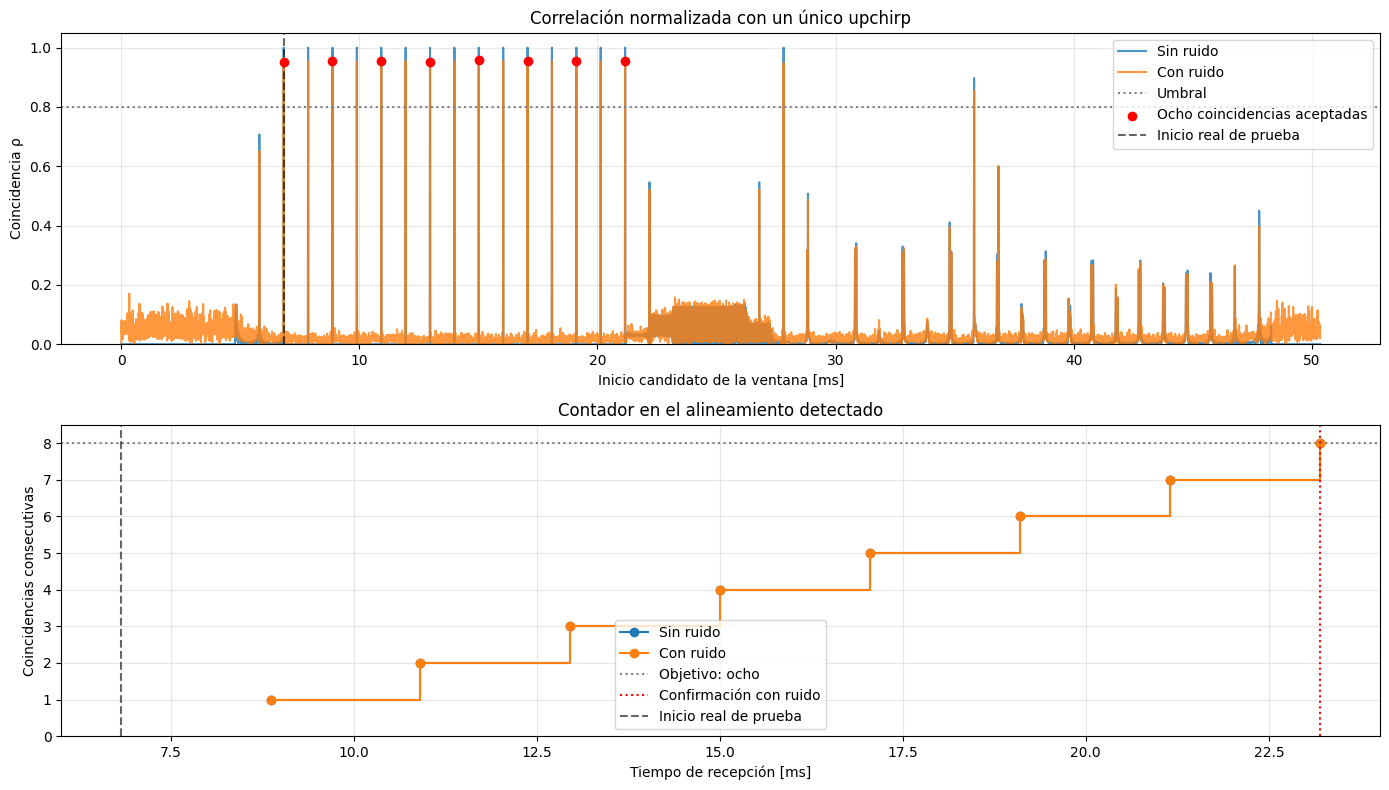

In [45]:
fig_un_up, ejes_un_up = plt.subplots(2, 1, figsize=(14, 8))
for nombre, resultado in (("Sin ruido", resultado_up_ideal), ("Con ruido", resultado_up_ruido)):
    tiempos = np.arange(resultado["coincidencia"].size) / B_TRAMA * 1000
    ejes_un_up[0].plot(tiempos, resultado["coincidencia"], label=nombre, alpha=0.8)
ejes_un_up[0].axhline(UMBRAL_UPCHIRP, color="gray", linestyle=":", label="Umbral")
if resultado_up_ruido["detectado"]:
    posiciones = resultado_up_ruido["posiciones_coincidencias"]
    ejes_un_up[0].scatter(posiciones / B_TRAMA * 1000,
                          resultado_up_ruido["coincidencias_aceptadas"],
                          color="red", zorder=5, label="Ocho coincidencias aceptadas")
ejes_un_up[0].set(title="Correlación normalizada con un único upchirp", ylabel="Coincidencia ρ")
ejes_un_up[0].set_ylim(0, 1.05)

for nombre, resultado in (("Sin ruido", resultado_up_ideal), ("Con ruido", resultado_up_ruido)):
    if resultado["detectado"]:
        posiciones = resultado["posiciones_coincidencias"]
        # Cada valor del contador se conoce al terminar su ventana de N muestras.
        fin_ventanas = posiciones + N_TRAMA - 1
        ejes_un_up[1].step(fin_ventanas / B_TRAMA * 1000,
                           resultado["contador"][posiciones], where="post", marker="o", label=nombre)
ejes_un_up[1].axhline(CANTIDAD_COINCIDENCIAS, color="gray", linestyle=":", label="Objetivo: ocho")
if resultado_up_ruido["detectado"]:
    ejes_un_up[1].axvline(resultado_up_ruido["muestra_confirmacion"] / B_TRAMA * 1000,
                          color="red", linestyle=":", label="Confirmación con ruido")
else:
    ejes_un_up[1].text(0.5, 0.5, "No se completó una cadena de ocho coincidencias con ruido.",
                       transform=ejes_un_up[1].transAxes, ha="center")
ejes_un_up[1].set(title="Contador en el alineamiento detectado", ylabel="Coincidencias consecutivas")
ejes_un_up[1].set_yticks(np.arange(CANTIDAD_COINCIDENCIAS + 1))
ejes_un_up[1].set_ylim(0, CANTIDAD_COINCIDENCIAS + 0.5)
for i, eje in enumerate(ejes_un_up):
    eje.axvline(RETARDO_PRUEBA / B_TRAMA * 1000, color="black", linestyle="--", alpha=0.6,
                label="Inicio real de prueba")
    eje.set_xlabel("Inicio candidato de la ventana [ms]" if i == 0 else "Tiempo de recepción [ms]")
    eje.grid(True, alpha=0.3)
    eje.legend()
fig_un_up.tight_layout()
plt.show()
